In [1]:
import pandas as pd, xarray as xr, numpy as np, matplotlib as mpl, geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt 
import pickle

from functions import reorient_netcdf, build_country_weights, \
                      verify_population_coverage, EU_MEMBERS, areaweighted_mean

In [2]:
## File path shortcuts
basepath = '/home/msaenger/Perceptions_2025/cleaned_code/'
cpath = basepath + 'CIDER_output/'

### Population-weighted latitude selection

In [4]:
## 2020 population data, already on the 96x192 model grid
pop = xr.open_dataarray(basepath + 'gpw-v4-population-count-rev11_totpop_96x192.nc').sel(time=2020)

countries_zip_path = basepath + 'natural_earth_data/ne_50m_admin_0_countries.zip'

country_weights_dict = build_country_weights(pop, countries_zip_path,
                keep_as_sovereign=['Palestine'], verbose=False)

verify_population_coverage(country_weights_dict)

W_norm_eu  = country_weights_dict['W_norm_eu']   
countries_idx_eu = country_weights_dict['countries_idx_eu']
country_da = country_weights_dict['country_da']
weights_2d = country_weights_dict['weights_2d']       
country_flat = country_weights_dict['country_flat']    
weights_flat_vals = country_weights_dict['weights_flat_vals']
folded_non_sovereign = country_weights_dict['folded_non_sovereign']
dropped_zero_pop = country_weights_dict['dropped_zero_pop']
population_total = country_weights_dict['population_total']
population_accounted = country_weights_dict['population_accounted']
population_coverage_frac = country_weights_dict['population_coverage_frac']

lon_grid, lat_grid = np.meshgrid(country_da['lon'].values, country_da['lat'].values)

PASSED -- Population coverage: 100.000000% (8.016736e+09 of 8.016736e+09 people-equivalent) accounted for across kept country rows.


In [5]:
def nearest_cider_lat_population_weighted(country_flat, weights_flat_vals, lat_grid, 
                                          cider_lats=np.array([-60, -30, -15, 0, 15, 30, 60]),
                                          eu_members=None):
    '''
    country_flat/weights_flat_vals only carry per-gridpoint country labels, so a plain
    factorize() here can never produce a 'European Union' row -- that label only exists
    as an aggregate added on top of country_weights_dict['countries_idx_eu'] downstream,
    never as a per-gridcell ADMIN value. Add it explicitly here, using the SAME
    unnormalized-sum-then-divide approach build_country_weights uses for its own EU row:
    sum the *unnormalized* weighted-lat and weight totals across whichever EU members are
    actually present, then divide once at the end. Averaging each member's own (already
    normalized) centroid instead would give e.g. Malta the same influence as Germany.

    eu_members : list of str, or None
        ADMIN names to aggregate into an additional 'European Union' row. Defaults to
        EU_MEMBERS (imported from Perceptions_functions). Pass [] to skip adding an EU row.
    '''
    if eu_members is None:
        eu_members = EU_MEMBERS

    cider_lats = np.asarray(cider_lats, dtype=float)
    lat_flat = lat_grid.ravel()

    valid = pd.notna(country_flat)
    codes, uniques = pd.factorize(country_flat[valid])

    weighted_lat_sum = np.bincount(codes, weights=weights_flat_vals[valid] * lat_flat[valid],
                                    minlength=len(uniques))
    
    weight_sum = np.bincount(codes, weights=weights_flat_vals[valid], minlength=len(uniques))

    # --- Aggregate EU member states into one additional 'European Union' row ---
    eu_members_found = [c for c in eu_members if c in uniques]
    missing = [c for c in eu_members if c not in uniques]
    if missing:
        print(f"Note: {len(missing)} EU countries have no grid coverage here and are "
              f"excluded from the EU centroid: {missing}")

    if eu_members_found:
        eu_mask = np.isin(uniques, eu_members_found)
        uniques = np.append(uniques, "European Union")
        weighted_lat_sum = np.append(weighted_lat_sum, weighted_lat_sum[eu_mask].sum())
        weight_sum = np.append(weight_sum, weight_sum[eu_mask].sum())

    pop_weighted_lat = weighted_lat_sum / weight_sum   # NaN for a country with all-zero pop weight

    dist = np.abs(pop_weighted_lat[:, None] - cider_lats[None, :])
    nearest_idx = dist.argmin(axis=1)

    return pd.DataFrame({
        'country': uniques,
        'pop_weighted_centroid_lat': pop_weighted_lat,
        'nearest_cider_lat': cider_lats[nearest_idx]})

In [6]:
cider_lat_df_popweighted = nearest_cider_lat_population_weighted(
                               country_flat, weights_flat_vals, lat_grid)

cider_lat_popweighted_da = cider_lat_df_popweighted.set_index('country').to_xarray()

# cider_lat_popweighted_da.to_netcdf(basepath + 'cider_injection_latitudes_by_country_popweighted.nc')

Note: 2 EU countries have no grid coverage here and are excluded from the EU centroid: ['Belgium', 'Luxembourg']


In [7]:
## Check that current version matches the one being uploaded

cider_inj_lats_popweighted = xr.open_dataset(basepath + \
                                'cider_injection_latitudes_by_country_popweighted.nc')
cider_inj_lats_popweighted.equals(cider_lat_popweighted_da)

True

In [8]:
## Create a single dataset to hold CIDER output for all injection latitudes and rates

cider_output_path = basepath + 'CIDER_output/'
print(cider_output_path)

def load_cider_combined(injection_paths, var, rates, n_months=60):
    
    """injection_paths: dict mapping injection_lat label -> folder path containing that
    label's rate files (e.g. {'60S': cider_single_lat_path + '60S/', 'uniform': cider_uniform_path})"""
    
    lat_das = []
    for label, folder in injection_paths.items():
        
        print(f'\n {folder} \n ')
        
        rate_das = []
        for i, rate in enumerate(rates):
            
            if rate % 2 == 0:
                fname = f'{(int(rate/2-1)):03d}_{rate:.1f}_Tgyr.nc_regridded.nc'
            
            else:
                fname = f'{(i+1)*5:04d}_{rate:.1f}_Tgyr.nc_regridded.nc'    
                
            print(fname)
            
            path = folder + fname

            da = reorient_netcdf(
                xr.open_dataset(path, chunks={'time': n_months})[var].isel(time=slice(0, n_months))
            )
            rate_das.append(da)
        lat_da = xr.concat(rate_das, dim=pd.Index(rates, name='injection_rate'))
        lat_das.append(lat_da)

    combined = xr.concat(lat_das, dim=pd.Index(list(injection_paths.keys()), name='injection_lat'))
    combined = combined.assign_coords(time=np.arange(n_months))
    combined = combined.load()
    
    return combined

/home/msaenger/Perceptions_2025/cleaned_code/CIDER_output/


In [9]:
lat_strs = ['60S', '30S', '15S', '0NS', '15N', '30N', '60N', 'uniform']
rates = np.arange(1.0, 250.01, 1.0)

In [10]:
injection_paths = {lat_str: cider_output_path + f'{lat_str}/' for lat_str in lat_strs}

cider_combined = load_cider_combined(injection_paths, ['T'], rates)
cider_combined


 /home/msaenger/Perceptions_2025/cleaned_code/CIDER_output/60S/ 
 
0005_1.0_Tgyr.nc_regridded.nc
000_2.0_Tgyr.nc_regridded.nc
0015_3.0_Tgyr.nc_regridded.nc
001_4.0_Tgyr.nc_regridded.nc
0025_5.0_Tgyr.nc_regridded.nc
002_6.0_Tgyr.nc_regridded.nc
0035_7.0_Tgyr.nc_regridded.nc
003_8.0_Tgyr.nc_regridded.nc
0045_9.0_Tgyr.nc_regridded.nc
004_10.0_Tgyr.nc_regridded.nc
0055_11.0_Tgyr.nc_regridded.nc
005_12.0_Tgyr.nc_regridded.nc
0065_13.0_Tgyr.nc_regridded.nc
006_14.0_Tgyr.nc_regridded.nc
0075_15.0_Tgyr.nc_regridded.nc
007_16.0_Tgyr.nc_regridded.nc
0085_17.0_Tgyr.nc_regridded.nc
008_18.0_Tgyr.nc_regridded.nc
0095_19.0_Tgyr.nc_regridded.nc
009_20.0_Tgyr.nc_regridded.nc
0105_21.0_Tgyr.nc_regridded.nc
010_22.0_Tgyr.nc_regridded.nc
0115_23.0_Tgyr.nc_regridded.nc
011_24.0_Tgyr.nc_regridded.nc
0125_25.0_Tgyr.nc_regridded.nc
012_26.0_Tgyr.nc_regridded.nc
0135_27.0_Tgyr.nc_regridded.nc
013_28.0_Tgyr.nc_regridded.nc
0145_29.0_Tgyr.nc_regridded.nc
014_30.0_Tgyr.nc_regridded.nc
0155_31.0_Tgyr.nc_regridde

0055_11.0_Tgyr.nc_regridded.nc
005_12.0_Tgyr.nc_regridded.nc
0065_13.0_Tgyr.nc_regridded.nc
006_14.0_Tgyr.nc_regridded.nc
0075_15.0_Tgyr.nc_regridded.nc
007_16.0_Tgyr.nc_regridded.nc
0085_17.0_Tgyr.nc_regridded.nc
008_18.0_Tgyr.nc_regridded.nc
0095_19.0_Tgyr.nc_regridded.nc
009_20.0_Tgyr.nc_regridded.nc
0105_21.0_Tgyr.nc_regridded.nc
010_22.0_Tgyr.nc_regridded.nc
0115_23.0_Tgyr.nc_regridded.nc
011_24.0_Tgyr.nc_regridded.nc
0125_25.0_Tgyr.nc_regridded.nc
012_26.0_Tgyr.nc_regridded.nc
0135_27.0_Tgyr.nc_regridded.nc
013_28.0_Tgyr.nc_regridded.nc
0145_29.0_Tgyr.nc_regridded.nc
014_30.0_Tgyr.nc_regridded.nc
0155_31.0_Tgyr.nc_regridded.nc
015_32.0_Tgyr.nc_regridded.nc
0165_33.0_Tgyr.nc_regridded.nc
016_34.0_Tgyr.nc_regridded.nc
0175_35.0_Tgyr.nc_regridded.nc
017_36.0_Tgyr.nc_regridded.nc
0185_37.0_Tgyr.nc_regridded.nc
018_38.0_Tgyr.nc_regridded.nc
0195_39.0_Tgyr.nc_regridded.nc
019_40.0_Tgyr.nc_regridded.nc
0205_41.0_Tgyr.nc_regridded.nc
020_42.0_Tgyr.nc_regridded.nc
0215_43.0_Tgyr.nc_regrid

0115_23.0_Tgyr.nc_regridded.nc
011_24.0_Tgyr.nc_regridded.nc
0125_25.0_Tgyr.nc_regridded.nc
012_26.0_Tgyr.nc_regridded.nc
0135_27.0_Tgyr.nc_regridded.nc
013_28.0_Tgyr.nc_regridded.nc
0145_29.0_Tgyr.nc_regridded.nc
014_30.0_Tgyr.nc_regridded.nc
0155_31.0_Tgyr.nc_regridded.nc
015_32.0_Tgyr.nc_regridded.nc
0165_33.0_Tgyr.nc_regridded.nc
016_34.0_Tgyr.nc_regridded.nc
0175_35.0_Tgyr.nc_regridded.nc
017_36.0_Tgyr.nc_regridded.nc
0185_37.0_Tgyr.nc_regridded.nc
018_38.0_Tgyr.nc_regridded.nc
0195_39.0_Tgyr.nc_regridded.nc
019_40.0_Tgyr.nc_regridded.nc
0205_41.0_Tgyr.nc_regridded.nc
020_42.0_Tgyr.nc_regridded.nc
0215_43.0_Tgyr.nc_regridded.nc
021_44.0_Tgyr.nc_regridded.nc
0225_45.0_Tgyr.nc_regridded.nc
022_46.0_Tgyr.nc_regridded.nc
0235_47.0_Tgyr.nc_regridded.nc
023_48.0_Tgyr.nc_regridded.nc
0245_49.0_Tgyr.nc_regridded.nc
024_50.0_Tgyr.nc_regridded.nc
0255_51.0_Tgyr.nc_regridded.nc
025_52.0_Tgyr.nc_regridded.nc
0265_53.0_Tgyr.nc_regridded.nc
026_54.0_Tgyr.nc_regridded.nc
0275_55.0_Tgyr.nc_regrid

017_36.0_Tgyr.nc_regridded.nc
0185_37.0_Tgyr.nc_regridded.nc
018_38.0_Tgyr.nc_regridded.nc
0195_39.0_Tgyr.nc_regridded.nc
019_40.0_Tgyr.nc_regridded.nc
0205_41.0_Tgyr.nc_regridded.nc
020_42.0_Tgyr.nc_regridded.nc
0215_43.0_Tgyr.nc_regridded.nc
021_44.0_Tgyr.nc_regridded.nc
0225_45.0_Tgyr.nc_regridded.nc
022_46.0_Tgyr.nc_regridded.nc
0235_47.0_Tgyr.nc_regridded.nc
023_48.0_Tgyr.nc_regridded.nc
0245_49.0_Tgyr.nc_regridded.nc
024_50.0_Tgyr.nc_regridded.nc
0255_51.0_Tgyr.nc_regridded.nc
025_52.0_Tgyr.nc_regridded.nc
0265_53.0_Tgyr.nc_regridded.nc
026_54.0_Tgyr.nc_regridded.nc
0275_55.0_Tgyr.nc_regridded.nc
027_56.0_Tgyr.nc_regridded.nc
0285_57.0_Tgyr.nc_regridded.nc
028_58.0_Tgyr.nc_regridded.nc
0295_59.0_Tgyr.nc_regridded.nc
029_60.0_Tgyr.nc_regridded.nc
0305_61.0_Tgyr.nc_regridded.nc
030_62.0_Tgyr.nc_regridded.nc
0315_63.0_Tgyr.nc_regridded.nc
031_64.0_Tgyr.nc_regridded.nc
0325_65.0_Tgyr.nc_regridded.nc
032_66.0_Tgyr.nc_regridded.nc
0335_67.0_Tgyr.nc_regridded.nc
033_68.0_Tgyr.nc_regridd

024_50.0_Tgyr.nc_regridded.nc
0255_51.0_Tgyr.nc_regridded.nc
025_52.0_Tgyr.nc_regridded.nc
0265_53.0_Tgyr.nc_regridded.nc
026_54.0_Tgyr.nc_regridded.nc
0275_55.0_Tgyr.nc_regridded.nc
027_56.0_Tgyr.nc_regridded.nc
0285_57.0_Tgyr.nc_regridded.nc
028_58.0_Tgyr.nc_regridded.nc
0295_59.0_Tgyr.nc_regridded.nc
029_60.0_Tgyr.nc_regridded.nc
0305_61.0_Tgyr.nc_regridded.nc
030_62.0_Tgyr.nc_regridded.nc
0315_63.0_Tgyr.nc_regridded.nc
031_64.0_Tgyr.nc_regridded.nc
0325_65.0_Tgyr.nc_regridded.nc
032_66.0_Tgyr.nc_regridded.nc
0335_67.0_Tgyr.nc_regridded.nc
033_68.0_Tgyr.nc_regridded.nc
0345_69.0_Tgyr.nc_regridded.nc
034_70.0_Tgyr.nc_regridded.nc
0355_71.0_Tgyr.nc_regridded.nc
035_72.0_Tgyr.nc_regridded.nc
0365_73.0_Tgyr.nc_regridded.nc
036_74.0_Tgyr.nc_regridded.nc
0375_75.0_Tgyr.nc_regridded.nc
037_76.0_Tgyr.nc_regridded.nc
0385_77.0_Tgyr.nc_regridded.nc
038_78.0_Tgyr.nc_regridded.nc
0395_79.0_Tgyr.nc_regridded.nc
039_80.0_Tgyr.nc_regridded.nc
0405_81.0_Tgyr.nc_regridded.nc
040_82.0_Tgyr.nc_regridd

030_62.0_Tgyr.nc_regridded.nc
0315_63.0_Tgyr.nc_regridded.nc
031_64.0_Tgyr.nc_regridded.nc
0325_65.0_Tgyr.nc_regridded.nc
032_66.0_Tgyr.nc_regridded.nc
0335_67.0_Tgyr.nc_regridded.nc
033_68.0_Tgyr.nc_regridded.nc
0345_69.0_Tgyr.nc_regridded.nc
034_70.0_Tgyr.nc_regridded.nc
0355_71.0_Tgyr.nc_regridded.nc
035_72.0_Tgyr.nc_regridded.nc
0365_73.0_Tgyr.nc_regridded.nc
036_74.0_Tgyr.nc_regridded.nc
0375_75.0_Tgyr.nc_regridded.nc
037_76.0_Tgyr.nc_regridded.nc
0385_77.0_Tgyr.nc_regridded.nc
038_78.0_Tgyr.nc_regridded.nc
0395_79.0_Tgyr.nc_regridded.nc
039_80.0_Tgyr.nc_regridded.nc
0405_81.0_Tgyr.nc_regridded.nc
040_82.0_Tgyr.nc_regridded.nc
0415_83.0_Tgyr.nc_regridded.nc
041_84.0_Tgyr.nc_regridded.nc
0425_85.0_Tgyr.nc_regridded.nc
042_86.0_Tgyr.nc_regridded.nc
0435_87.0_Tgyr.nc_regridded.nc
043_88.0_Tgyr.nc_regridded.nc
0445_89.0_Tgyr.nc_regridded.nc
044_90.0_Tgyr.nc_regridded.nc
0455_91.0_Tgyr.nc_regridded.nc
045_92.0_Tgyr.nc_regridded.nc
0465_93.0_Tgyr.nc_regridded.nc
046_94.0_Tgyr.nc_regridd

0375_75.0_Tgyr.nc_regridded.nc
037_76.0_Tgyr.nc_regridded.nc
0385_77.0_Tgyr.nc_regridded.nc
038_78.0_Tgyr.nc_regridded.nc
0395_79.0_Tgyr.nc_regridded.nc
039_80.0_Tgyr.nc_regridded.nc
0405_81.0_Tgyr.nc_regridded.nc
040_82.0_Tgyr.nc_regridded.nc
0415_83.0_Tgyr.nc_regridded.nc
041_84.0_Tgyr.nc_regridded.nc
0425_85.0_Tgyr.nc_regridded.nc
042_86.0_Tgyr.nc_regridded.nc
0435_87.0_Tgyr.nc_regridded.nc
043_88.0_Tgyr.nc_regridded.nc
0445_89.0_Tgyr.nc_regridded.nc
044_90.0_Tgyr.nc_regridded.nc
0455_91.0_Tgyr.nc_regridded.nc
045_92.0_Tgyr.nc_regridded.nc
0465_93.0_Tgyr.nc_regridded.nc
046_94.0_Tgyr.nc_regridded.nc
0475_95.0_Tgyr.nc_regridded.nc
047_96.0_Tgyr.nc_regridded.nc
0485_97.0_Tgyr.nc_regridded.nc
048_98.0_Tgyr.nc_regridded.nc
0495_99.0_Tgyr.nc_regridded.nc
049_100.0_Tgyr.nc_regridded.nc
0505_101.0_Tgyr.nc_regridded.nc
050_102.0_Tgyr.nc_regridded.nc
0515_103.0_Tgyr.nc_regridded.nc
051_104.0_Tgyr.nc_regridded.nc
0525_105.0_Tgyr.nc_regridded.nc
052_106.0_Tgyr.nc_regridded.nc
0535_107.0_Tgyr.n

043_88.0_Tgyr.nc_regridded.nc
0445_89.0_Tgyr.nc_regridded.nc
044_90.0_Tgyr.nc_regridded.nc
0455_91.0_Tgyr.nc_regridded.nc
045_92.0_Tgyr.nc_regridded.nc
0465_93.0_Tgyr.nc_regridded.nc
046_94.0_Tgyr.nc_regridded.nc
0475_95.0_Tgyr.nc_regridded.nc
047_96.0_Tgyr.nc_regridded.nc
0485_97.0_Tgyr.nc_regridded.nc
048_98.0_Tgyr.nc_regridded.nc
0495_99.0_Tgyr.nc_regridded.nc
049_100.0_Tgyr.nc_regridded.nc
0505_101.0_Tgyr.nc_regridded.nc
050_102.0_Tgyr.nc_regridded.nc
0515_103.0_Tgyr.nc_regridded.nc
051_104.0_Tgyr.nc_regridded.nc
0525_105.0_Tgyr.nc_regridded.nc
052_106.0_Tgyr.nc_regridded.nc
0535_107.0_Tgyr.nc_regridded.nc
053_108.0_Tgyr.nc_regridded.nc
0545_109.0_Tgyr.nc_regridded.nc
054_110.0_Tgyr.nc_regridded.nc
0555_111.0_Tgyr.nc_regridded.nc
055_112.0_Tgyr.nc_regridded.nc
0565_113.0_Tgyr.nc_regridded.nc
056_114.0_Tgyr.nc_regridded.nc
0575_115.0_Tgyr.nc_regridded.nc
057_116.0_Tgyr.nc_regridded.nc
0585_117.0_Tgyr.nc_regridded.nc
058_118.0_Tgyr.nc_regridded.nc
0595_119.0_Tgyr.nc_regridded.nc
059_

<xarray.Dataset> Size: 18GB
Dimensions:         (injection_lat: 8, injection_rate: 250, time: 60, lat: 96,
                     lon: 192)
Coordinates:
  * lat             (lat) float64 768B -88.57 -86.72 -84.86 ... 86.72 88.57
  * lon             (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
  * injection_rate  (injection_rate) float64 2kB 1.0 2.0 3.0 ... 249.0 250.0
  * injection_lat   (injection_lat) object 64B '60S' '30S' ... '60N' 'uniform'
  * time            (time) int64 480B 0 1 2 3 4 5 6 7 ... 53 54 55 56 57 58 59
Data variables:
    T               (injection_lat, injection_rate, time, lat, lon) float64 18GB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  Dataset converted from NumPy array with dimensions (lon, la...
    history:      Tue Jul 28 15:54:18 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [11]:
cider_combined

<xarray.Dataset> Size: 18GB
Dimensions:         (injection_lat: 8, injection_rate: 250, time: 60, lat: 96,
                     lon: 192)
Coordinates:
  * lat             (lat) float64 768B -88.57 -86.72 -84.86 ... 86.72 88.57
  * lon             (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
  * injection_rate  (injection_rate) float64 2kB 1.0 2.0 3.0 ... 249.0 250.0
  * injection_lat   (injection_lat) object 64B '60S' '30S' ... '60N' 'uniform'
  * time            (time) int64 480B 0 1 2 3 4 5 6 7 ... 53 54 55 56 57 58 59
Data variables:
    T               (injection_lat, injection_rate, time, lat, lon) float64 18GB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  Dataset converted from NumPy array with dimensions (lon, la...
    history:      Tue Jul 28 15:54:18 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

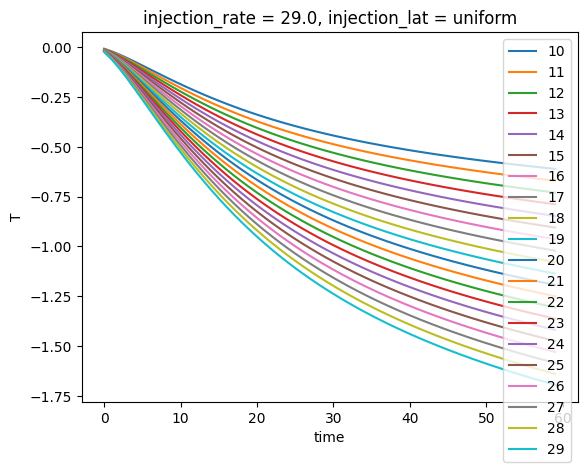

In [12]:
## Check thate injection rates were added in correct ascending order with correct label

for rate in range(10, 30):

    areaweighted_mean(cider_combined['T'].sel(
                injection_lat='uniform').sel(injection_rate=rate)).plot(label=rate)
    plt.legend()

In [13]:
# cider_combined.to_netcdf(cpath + 'CIDER_TREFHT_output_combined_1.0_Tg_increments_first_5_years.nc')

test = xr.open_dataset(cpath + 'CIDER_TREFHT_output_combined_1.0_Tg_increments_first_5_years.nc')

test.equals(cider_combined)

True

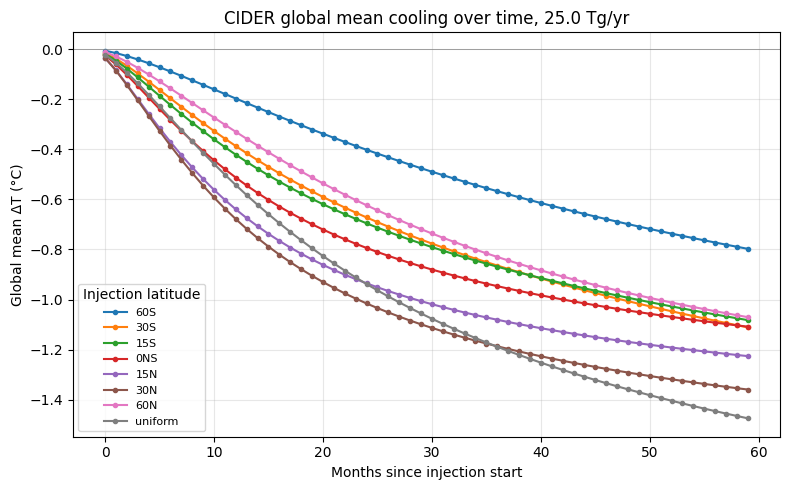

In [14]:
import matplotlib.pyplot as plt

var = 'T'

rate_to_plot = 25.0   # Tg/yr -- pick whichever rate you want to inspect

global_mean_dT = areaweighted_mean(cider_combined[var].sel(injection_rate = rate_to_plot))


fig, ax = plt.subplots(figsize=(8, 5))
for inj_lat in global_mean_dT.injection_lat.values:
    series = global_mean_dT.sel(injection_lat=inj_lat)
    
    ax.plot(series.time.values, series.values, 
            marker='o', markersize=3, label=inj_lat)

ax.axhline(0, color='gray', linewidth=0.5)
ax.set_xlabel('Months since injection start')
ax.set_ylabel('Global mean ΔT (°C)')
ax.set_title(f'CIDER global mean cooling over time, {rate_to_plot} Tg/yr')
ax.legend(title='Injection latitude', fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## PRECIP


In [15]:
## Create a single dataset to hold CIDER output for all injection latitudes and rates

cider_output_path = basepath + 'CIDER_output/PRECIP/'
print(cider_output_path)

injection_paths = {lat_str: cider_output_path + f'{lat_str}/' for lat_str in lat_strs}

cider_combined = load_cider_combined(injection_paths, ['P'], rates)
cider_combined

/home/msaenger/Perceptions_2025/cleaned_code/CIDER_output/PRECIP/

 /home/msaenger/Perceptions_2025/cleaned_code/CIDER_output/PRECIP/60S/ 
 
0005_1.0_Tgyr.nc_regridded.nc
000_2.0_Tgyr.nc_regridded.nc
0015_3.0_Tgyr.nc_regridded.nc
001_4.0_Tgyr.nc_regridded.nc
0025_5.0_Tgyr.nc_regridded.nc
002_6.0_Tgyr.nc_regridded.nc
0035_7.0_Tgyr.nc_regridded.nc
003_8.0_Tgyr.nc_regridded.nc
0045_9.0_Tgyr.nc_regridded.nc
004_10.0_Tgyr.nc_regridded.nc
0055_11.0_Tgyr.nc_regridded.nc
005_12.0_Tgyr.nc_regridded.nc
0065_13.0_Tgyr.nc_regridded.nc
006_14.0_Tgyr.nc_regridded.nc
0075_15.0_Tgyr.nc_regridded.nc
007_16.0_Tgyr.nc_regridded.nc
0085_17.0_Tgyr.nc_regridded.nc
008_18.0_Tgyr.nc_regridded.nc
0095_19.0_Tgyr.nc_regridded.nc
009_20.0_Tgyr.nc_regridded.nc
0105_21.0_Tgyr.nc_regridded.nc
010_22.0_Tgyr.nc_regridded.nc
0115_23.0_Tgyr.nc_regridded.nc
011_24.0_Tgyr.nc_regridded.nc
0125_25.0_Tgyr.nc_regridded.nc
012_26.0_Tgyr.nc_regridded.nc
0135_27.0_Tgyr.nc_regridded.nc
013_28.0_Tgyr.nc_regridded.nc
0145_29.0_Tgyr

004_10.0_Tgyr.nc_regridded.nc
0055_11.0_Tgyr.nc_regridded.nc
005_12.0_Tgyr.nc_regridded.nc
0065_13.0_Tgyr.nc_regridded.nc
006_14.0_Tgyr.nc_regridded.nc
0075_15.0_Tgyr.nc_regridded.nc
007_16.0_Tgyr.nc_regridded.nc
0085_17.0_Tgyr.nc_regridded.nc
008_18.0_Tgyr.nc_regridded.nc
0095_19.0_Tgyr.nc_regridded.nc
009_20.0_Tgyr.nc_regridded.nc
0105_21.0_Tgyr.nc_regridded.nc
010_22.0_Tgyr.nc_regridded.nc
0115_23.0_Tgyr.nc_regridded.nc
011_24.0_Tgyr.nc_regridded.nc
0125_25.0_Tgyr.nc_regridded.nc
012_26.0_Tgyr.nc_regridded.nc
0135_27.0_Tgyr.nc_regridded.nc
013_28.0_Tgyr.nc_regridded.nc
0145_29.0_Tgyr.nc_regridded.nc
014_30.0_Tgyr.nc_regridded.nc
0155_31.0_Tgyr.nc_regridded.nc
015_32.0_Tgyr.nc_regridded.nc
0165_33.0_Tgyr.nc_regridded.nc
016_34.0_Tgyr.nc_regridded.nc
0175_35.0_Tgyr.nc_regridded.nc
017_36.0_Tgyr.nc_regridded.nc
0185_37.0_Tgyr.nc_regridded.nc
018_38.0_Tgyr.nc_regridded.nc
0195_39.0_Tgyr.nc_regridded.nc
019_40.0_Tgyr.nc_regridded.nc
0205_41.0_Tgyr.nc_regridded.nc
020_42.0_Tgyr.nc_regridd

010_22.0_Tgyr.nc_regridded.nc
0115_23.0_Tgyr.nc_regridded.nc
011_24.0_Tgyr.nc_regridded.nc
0125_25.0_Tgyr.nc_regridded.nc
012_26.0_Tgyr.nc_regridded.nc
0135_27.0_Tgyr.nc_regridded.nc
013_28.0_Tgyr.nc_regridded.nc
0145_29.0_Tgyr.nc_regridded.nc
014_30.0_Tgyr.nc_regridded.nc
0155_31.0_Tgyr.nc_regridded.nc
015_32.0_Tgyr.nc_regridded.nc
0165_33.0_Tgyr.nc_regridded.nc
016_34.0_Tgyr.nc_regridded.nc
0175_35.0_Tgyr.nc_regridded.nc
017_36.0_Tgyr.nc_regridded.nc
0185_37.0_Tgyr.nc_regridded.nc
018_38.0_Tgyr.nc_regridded.nc
0195_39.0_Tgyr.nc_regridded.nc
019_40.0_Tgyr.nc_regridded.nc
0205_41.0_Tgyr.nc_regridded.nc
020_42.0_Tgyr.nc_regridded.nc
0215_43.0_Tgyr.nc_regridded.nc
021_44.0_Tgyr.nc_regridded.nc
0225_45.0_Tgyr.nc_regridded.nc
022_46.0_Tgyr.nc_regridded.nc
0235_47.0_Tgyr.nc_regridded.nc
023_48.0_Tgyr.nc_regridded.nc
0245_49.0_Tgyr.nc_regridded.nc
024_50.0_Tgyr.nc_regridded.nc
0255_51.0_Tgyr.nc_regridded.nc
025_52.0_Tgyr.nc_regridded.nc
0265_53.0_Tgyr.nc_regridded.nc
026_54.0_Tgyr.nc_regridd

016_34.0_Tgyr.nc_regridded.nc
0175_35.0_Tgyr.nc_regridded.nc
017_36.0_Tgyr.nc_regridded.nc
0185_37.0_Tgyr.nc_regridded.nc
018_38.0_Tgyr.nc_regridded.nc
0195_39.0_Tgyr.nc_regridded.nc
019_40.0_Tgyr.nc_regridded.nc
0205_41.0_Tgyr.nc_regridded.nc
020_42.0_Tgyr.nc_regridded.nc
0215_43.0_Tgyr.nc_regridded.nc
021_44.0_Tgyr.nc_regridded.nc
0225_45.0_Tgyr.nc_regridded.nc
022_46.0_Tgyr.nc_regridded.nc
0235_47.0_Tgyr.nc_regridded.nc
023_48.0_Tgyr.nc_regridded.nc
0245_49.0_Tgyr.nc_regridded.nc
024_50.0_Tgyr.nc_regridded.nc
0255_51.0_Tgyr.nc_regridded.nc
025_52.0_Tgyr.nc_regridded.nc
0265_53.0_Tgyr.nc_regridded.nc
026_54.0_Tgyr.nc_regridded.nc
0275_55.0_Tgyr.nc_regridded.nc
027_56.0_Tgyr.nc_regridded.nc
0285_57.0_Tgyr.nc_regridded.nc
028_58.0_Tgyr.nc_regridded.nc
0295_59.0_Tgyr.nc_regridded.nc
029_60.0_Tgyr.nc_regridded.nc
0305_61.0_Tgyr.nc_regridded.nc
030_62.0_Tgyr.nc_regridded.nc
0315_63.0_Tgyr.nc_regridded.nc
031_64.0_Tgyr.nc_regridded.nc
0325_65.0_Tgyr.nc_regridded.nc
032_66.0_Tgyr.nc_regridd

0235_47.0_Tgyr.nc_regridded.nc
023_48.0_Tgyr.nc_regridded.nc
0245_49.0_Tgyr.nc_regridded.nc
024_50.0_Tgyr.nc_regridded.nc
0255_51.0_Tgyr.nc_regridded.nc
025_52.0_Tgyr.nc_regridded.nc
0265_53.0_Tgyr.nc_regridded.nc
026_54.0_Tgyr.nc_regridded.nc
0275_55.0_Tgyr.nc_regridded.nc
027_56.0_Tgyr.nc_regridded.nc
0285_57.0_Tgyr.nc_regridded.nc
028_58.0_Tgyr.nc_regridded.nc
0295_59.0_Tgyr.nc_regridded.nc
029_60.0_Tgyr.nc_regridded.nc
0305_61.0_Tgyr.nc_regridded.nc
030_62.0_Tgyr.nc_regridded.nc
0315_63.0_Tgyr.nc_regridded.nc
031_64.0_Tgyr.nc_regridded.nc
0325_65.0_Tgyr.nc_regridded.nc
032_66.0_Tgyr.nc_regridded.nc
0335_67.0_Tgyr.nc_regridded.nc
033_68.0_Tgyr.nc_regridded.nc
0345_69.0_Tgyr.nc_regridded.nc
034_70.0_Tgyr.nc_regridded.nc
0355_71.0_Tgyr.nc_regridded.nc
035_72.0_Tgyr.nc_regridded.nc
0365_73.0_Tgyr.nc_regridded.nc
036_74.0_Tgyr.nc_regridded.nc
0375_75.0_Tgyr.nc_regridded.nc
037_76.0_Tgyr.nc_regridded.nc
0385_77.0_Tgyr.nc_regridded.nc
038_78.0_Tgyr.nc_regridded.nc
0395_79.0_Tgyr.nc_regrid

029_60.0_Tgyr.nc_regridded.nc
0305_61.0_Tgyr.nc_regridded.nc
030_62.0_Tgyr.nc_regridded.nc
0315_63.0_Tgyr.nc_regridded.nc
031_64.0_Tgyr.nc_regridded.nc
0325_65.0_Tgyr.nc_regridded.nc
032_66.0_Tgyr.nc_regridded.nc
0335_67.0_Tgyr.nc_regridded.nc
033_68.0_Tgyr.nc_regridded.nc
0345_69.0_Tgyr.nc_regridded.nc
034_70.0_Tgyr.nc_regridded.nc
0355_71.0_Tgyr.nc_regridded.nc
035_72.0_Tgyr.nc_regridded.nc
0365_73.0_Tgyr.nc_regridded.nc
036_74.0_Tgyr.nc_regridded.nc
0375_75.0_Tgyr.nc_regridded.nc
037_76.0_Tgyr.nc_regridded.nc
0385_77.0_Tgyr.nc_regridded.nc
038_78.0_Tgyr.nc_regridded.nc
0395_79.0_Tgyr.nc_regridded.nc
039_80.0_Tgyr.nc_regridded.nc
0405_81.0_Tgyr.nc_regridded.nc
040_82.0_Tgyr.nc_regridded.nc
0415_83.0_Tgyr.nc_regridded.nc
041_84.0_Tgyr.nc_regridded.nc
0425_85.0_Tgyr.nc_regridded.nc
042_86.0_Tgyr.nc_regridded.nc
0435_87.0_Tgyr.nc_regridded.nc
043_88.0_Tgyr.nc_regridded.nc
0445_89.0_Tgyr.nc_regridded.nc
044_90.0_Tgyr.nc_regridded.nc
0455_91.0_Tgyr.nc_regridded.nc
045_92.0_Tgyr.nc_regridd

035_72.0_Tgyr.nc_regridded.nc
0365_73.0_Tgyr.nc_regridded.nc
036_74.0_Tgyr.nc_regridded.nc
0375_75.0_Tgyr.nc_regridded.nc
037_76.0_Tgyr.nc_regridded.nc
0385_77.0_Tgyr.nc_regridded.nc
038_78.0_Tgyr.nc_regridded.nc
0395_79.0_Tgyr.nc_regridded.nc
039_80.0_Tgyr.nc_regridded.nc
0405_81.0_Tgyr.nc_regridded.nc
040_82.0_Tgyr.nc_regridded.nc
0415_83.0_Tgyr.nc_regridded.nc
041_84.0_Tgyr.nc_regridded.nc
0425_85.0_Tgyr.nc_regridded.nc
042_86.0_Tgyr.nc_regridded.nc
0435_87.0_Tgyr.nc_regridded.nc
043_88.0_Tgyr.nc_regridded.nc
0445_89.0_Tgyr.nc_regridded.nc
044_90.0_Tgyr.nc_regridded.nc
0455_91.0_Tgyr.nc_regridded.nc
045_92.0_Tgyr.nc_regridded.nc
0465_93.0_Tgyr.nc_regridded.nc
046_94.0_Tgyr.nc_regridded.nc
0475_95.0_Tgyr.nc_regridded.nc
047_96.0_Tgyr.nc_regridded.nc
0485_97.0_Tgyr.nc_regridded.nc
048_98.0_Tgyr.nc_regridded.nc
0495_99.0_Tgyr.nc_regridded.nc
049_100.0_Tgyr.nc_regridded.nc
0505_101.0_Tgyr.nc_regridded.nc
050_102.0_Tgyr.nc_regridded.nc
0515_103.0_Tgyr.nc_regridded.nc
051_104.0_Tgyr.nc_re

042_86.0_Tgyr.nc_regridded.nc
0435_87.0_Tgyr.nc_regridded.nc
043_88.0_Tgyr.nc_regridded.nc
0445_89.0_Tgyr.nc_regridded.nc
044_90.0_Tgyr.nc_regridded.nc
0455_91.0_Tgyr.nc_regridded.nc
045_92.0_Tgyr.nc_regridded.nc
0465_93.0_Tgyr.nc_regridded.nc
046_94.0_Tgyr.nc_regridded.nc
0475_95.0_Tgyr.nc_regridded.nc
047_96.0_Tgyr.nc_regridded.nc
0485_97.0_Tgyr.nc_regridded.nc
048_98.0_Tgyr.nc_regridded.nc
0495_99.0_Tgyr.nc_regridded.nc
049_100.0_Tgyr.nc_regridded.nc
0505_101.0_Tgyr.nc_regridded.nc
050_102.0_Tgyr.nc_regridded.nc
0515_103.0_Tgyr.nc_regridded.nc
051_104.0_Tgyr.nc_regridded.nc
0525_105.0_Tgyr.nc_regridded.nc
052_106.0_Tgyr.nc_regridded.nc
0535_107.0_Tgyr.nc_regridded.nc
053_108.0_Tgyr.nc_regridded.nc
0545_109.0_Tgyr.nc_regridded.nc
054_110.0_Tgyr.nc_regridded.nc
0555_111.0_Tgyr.nc_regridded.nc
055_112.0_Tgyr.nc_regridded.nc
0565_113.0_Tgyr.nc_regridded.nc
056_114.0_Tgyr.nc_regridded.nc
0575_115.0_Tgyr.nc_regridded.nc
057_116.0_Tgyr.nc_regridded.nc
0585_117.0_Tgyr.nc_regridded.nc
058_11

<xarray.Dataset> Size: 18GB
Dimensions:         (injection_lat: 8, injection_rate: 250, time: 60, lat: 96,
                     lon: 192)
Coordinates:
  * lat             (lat) float64 768B -88.57 -86.72 -84.86 ... 86.72 88.57
  * lon             (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
  * injection_rate  (injection_rate) float64 2kB 1.0 2.0 3.0 ... 249.0 250.0
  * injection_lat   (injection_lat) object 64B '60S' '30S' ... '60N' 'uniform'
  * time            (time) int64 480B 0 1 2 3 4 5 6 7 ... 53 54 55 56 57 58 59
Data variables:
    P               (injection_lat, injection_rate, time, lat, lon) float64 18GB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  Dataset converted from NumPy array with dimensions (lon, la...
    history:      Thu Jul 30 14:43:17 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [16]:
cider_combined

<xarray.Dataset> Size: 18GB
Dimensions:         (injection_lat: 8, injection_rate: 250, time: 60, lat: 96,
                     lon: 192)
Coordinates:
  * lat             (lat) float64 768B -88.57 -86.72 -84.86 ... 86.72 88.57
  * lon             (lon) float64 2kB -178.1 -176.2 -174.4 ... 176.2 178.1 180.0
  * injection_rate  (injection_rate) float64 2kB 1.0 2.0 3.0 ... 249.0 250.0
  * injection_lat   (injection_lat) object 64B '60S' '30S' ... '60N' 'uniform'
  * time            (time) int64 480B 0 1 2 3 4 5 6 7 ... 53 54 55 56 57 58 59
Data variables:
    P               (injection_lat, injection_rate, time, lat, lon) float64 18GB ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    description:  Dataset converted from NumPy array with dimensions (lon, la...
    history:      Thu Jul 30 14:43:17 2026: cdo -remapbil,/home/msaenger/REST...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

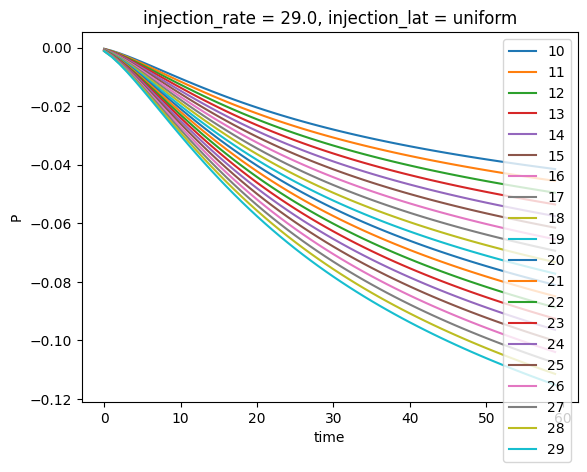

In [17]:
## Check thate injection rates were added in correct ascending order with correct label

for rate in range(10, 30):

    areaweighted_mean(cider_combined['P'].sel(
                injection_lat='uniform').sel(injection_rate=rate)).plot(label=rate)
    plt.legend()

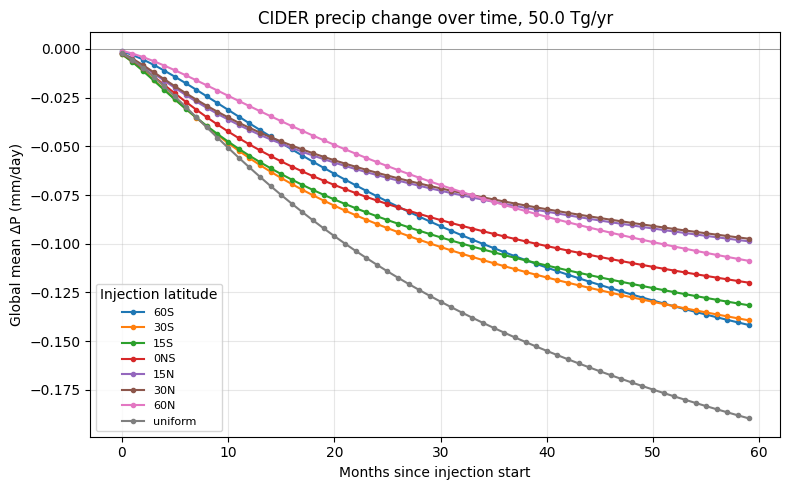

In [18]:
rate_to_plot = 50.0   # Tg/yr -- pick whichever rate you want to inspect

global_mean_dP = areaweighted_mean(cider_combined['P'])

series_at_rate = global_mean_dP.sel(injection_rate=rate_to_plot)   # (injection_lat, time)

fig, ax = plt.subplots(figsize=(8, 5))
for inj_lat in series_at_rate.injection_lat.values:
    series = series_at_rate.sel(injection_lat=inj_lat)
    ax.plot(series.time.values, series.values, 
            marker='o', markersize=3, label=inj_lat)

ax.axhline(0, color='gray', linewidth=0.5)
ax.set_xlabel('Months since injection start')
ax.set_ylabel('Global mean ΔP (mm/day)')
ax.set_title(f'CIDER precip change over time, {rate_to_plot} Tg/yr')
ax.legend(title='Injection latitude', fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Save combined CIDER output for precip

# cider_combined.to_netcdf(cider_output_path + \
#                 'CIDER_PRECT_output_combined_1.0_Tg_increments_first_5_years.nc')

In [20]:
test = xr.open_dataset(cider_output_path + \
                'CIDER_PRECT_output_combined_1.0_Tg_increments_first_5_years.nc')

test.equals(cider_combined)

True